# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [1]:
# YOUR CODE HERE
from google.colab import drive
drive.mount('/content/drive')

import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

from datasets import load_from_disk

DRIVE_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"

tokenized_train = load_from_disk(DRIVE_DIR + "/tokenized_train")
tokenized_valid = load_from_disk(DRIVE_DIR + "/tokenized_valid")

print("")
print("tokenized_train:", len(tokenized_train), "rows")
print("tokenized_valid:", len(tokenized_valid), "rows")
print("")
print("Schema:", tokenized_train.column_names)

non_masked = sum(1 for l in tokenized_train[0]["labels"] if l != -100)
print("Sample row 0 non-masked label tokens:", non_masked)

# ============================================================
# Load base model in 4-bit, then wrap with LoRA adapters
# ============================================================

!pip install -q -U bitsandbytes accelerate peft

from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"  # must match every prior notebook exactly

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("")
print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Loading base model in 4-bit...")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)

print("")
print("Preparing model for k-bit training (enables gradient checkpointing, casts norm layers to fp32)...")
base_model = prepare_model_for_kbit_training(base_model)

# ------------------------------------------------------------
# LoRA config: r=16, alpha=32 (2x rule of thumb), targeting
# q_proj and v_proj per the task's minimum spec
# ------------------------------------------------------------
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q_proj", "v_proj"]

lora_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    target_modules=TARGET_MODULES,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type="CAUSAL_LM"
)

print("")
print("Applying LoRA adapter with config:")
print("  r =", LORA_R)
print("  lora_alpha =", LORA_ALPHA)
print("  lora_dropout =", LORA_DROPOUT)
print("  target_modules =", TARGET_MODULES)

peft_model = get_peft_model(base_model, lora_config)

print("")
print("--- Trainable parameter summary ---")
peft_model.print_trainable_parameters()

# ------------------------------------------------------------
# Explicit verification: confirm LoRA layers actually attached
# to q_proj / v_proj, and that everything else is frozen
# ------------------------------------------------------------
print("")
print("--- Verification: LoRA modules attached ---")
lora_module_names = set()
for name, module in peft_model.named_modules():
    if "lora" in name.lower():
        # Extract the parent module name (e.g. "...layers.0.self_attn.q_proj")
        parent = name.rsplit(".lora", 1)[0]
        lora_module_names.add(parent.split(".")[-1])

print("Modules with LoRA adapters attached:", lora_module_names)

expected = set(TARGET_MODULES)
if lora_module_names == expected:
    print("CONFIRMED: LoRA correctly attached to exactly", expected)
else:
    print("WARNING: mismatch - expected", expected, "found", lora_module_names)

trainable_count = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
total_count = sum(p.numel() for p in peft_model.parameters())
trainable_pct = 100 * trainable_count / total_count

print("")
print("Trainable params:", trainable_count)
print("Total params:", total_count)
print("Trainable percent:", round(trainable_pct, 3), "percent")

if trainable_pct > 2:
    print("WARNING: trainable percent higher than the expected ~0.5-1 percent range - check target_modules")
else:
    print("Trainable percent within expected range for LoRA on q_proj/v_proj.")

Mounted at /content/drive
CUDA available: True
GPU: Tesla T4

tokenized_train: 3121 rows
tokenized_valid: 390 rows

Schema: ['input_ids', 'attention_mask', 'labels', 'intent', 'category', 'instruction']
Sample row 0 non-masked label tokens: 15
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 27.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 42.3 MB/s eta 0:00:00

Loading tokenizer...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Preparing model for k-bit training (enables gradient checkpointing, casts norm layers to fp32)...

Applying LoRA adapter with config:
  r = 16
  lora_alpha = 32
  lora_dropout = 0.05
  target_modules = ['q_proj', 'v_proj']

--- Trainable parameter summary ---
trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410

--- Verification: LoRA modules attached ---
Modules with LoRA adapters attached: {'q_proj', 'v_proj'}
CONFIRMED: LoRA correctly attached to exactly {'q_proj', 'v_proj'}

Trainable params: 2179072
Total params: 890795520
Trainable percent: 0.245 percent
Trainable percent within expected range for LoRA on q_proj/v_proj.


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [2]:
# YOUR CODE HERE
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW

# ------------------------------------------------------------
# 1. Set tensor format so DataLoader yields torch tensors
#    directly (required after load_from_disk, which stores
#    columns as plain Python lists)
# ------------------------------------------------------------
tokenized_train.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
tokenized_valid.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

print("tokenized_train format set. Sample input_ids type:", type(tokenized_train[0]["input_ids"]))
print("tokenized_valid format set. Sample input_ids type:", type(tokenized_valid[0]["input_ids"]))

# ------------------------------------------------------------
# 2. Hyperparameters
# ------------------------------------------------------------
LEARNING_RATE = 2e-4
BATCH_SIZE = 4        # drop to 2 if you hit OOM on T4
MAX_STEPS = 400        # ~1 epoch on 3121 rows at batch_size=4 (3121/4 ≈ 780 steps/epoch,
                        # so 400 covers roughly half an epoch - bump to ~780 for a full epoch)
VAL_EVERY = 10          # run validation every N training steps
PATIENCE = 3            # early-stopping patience, in validation checks (not steps)

print("")
print("--- Hyperparameters ---")
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Max steps:", MAX_STEPS)
print("Val every:", VAL_EVERY, "steps")
print("Early stopping patience:", PATIENCE, "validation checks")

steps_per_epoch = len(tokenized_train) // BATCH_SIZE
approx_epochs = MAX_STEPS / steps_per_epoch
print("Steps per full epoch (approx):", steps_per_epoch)
print("MAX_STEPS corresponds to approximately", round(approx_epochs, 2), "epochs")

# ------------------------------------------------------------
# 3. DataLoaders
# ------------------------------------------------------------
train_loader = DataLoader(tokenized_train, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(tokenized_valid, batch_size=BATCH_SIZE, shuffle=False)

print("")
print("Train batches per epoch:", len(train_loader))
print("Valid batches:", len(valid_loader))

# ------------------------------------------------------------
# 4. Optimiser - AdamW over only the trainable (LoRA) parameters
# ------------------------------------------------------------
trainable_params = filter(lambda p: p.requires_grad, peft_model.parameters())
optimizer = AdamW(trainable_params, lr=LEARNING_RATE)

trainable_param_count = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
print("")
print("AdamW optimizer initialised over", trainable_param_count, "trainable parameters")

# ------------------------------------------------------------
# 5. Quick sanity check: pull one batch through the model
#    end-to-end (forward pass only) before committing to a
#    full training loop, to catch shape/device errors early
# ------------------------------------------------------------
sample_batch = next(iter(train_loader))
print("")
print("--- Sample batch shapes ---")
print("input_ids:", sample_batch["input_ids"].shape)
print("attention_mask:", sample_batch["attention_mask"].shape)
print("labels:", sample_batch["labels"].shape)

sample_batch_gpu = {k: v.to(peft_model.device) for k, v in sample_batch.items()}

peft_model.eval()
with torch.no_grad():
    test_output = peft_model(**sample_batch_gpu)

print("")
print("Forward pass successful.")
print("Loss on sample batch (model's internal loss, from labels):", test_output.loss.item())

peft_model.train()
print("")
print("Setup complete: optimizer, DataLoaders, and hyperparameters ready for the training loop.")

tokenized_train format set. Sample input_ids type: <class 'torch.Tensor'>
tokenized_valid format set. Sample input_ids type: <class 'torch.Tensor'>

--- Hyperparameters ---
Learning rate: 0.0002
Batch size: 4
Max steps: 400
Val every: 10 steps
Early stopping patience: 3 validation checks
Steps per full epoch (approx): 780
MAX_STEPS corresponds to approximately 0.51 epochs

Train batches per epoch: 781
Valid batches: 98

AdamW optimizer initialised over 2179072 trainable parameters

--- Sample batch shapes ---
input_ids: torch.Size([4, 128])
attention_mask: torch.Size([4, 128])
labels: torch.Size([4, 128])

Forward pass successful.
Loss on sample batch (model's internal loss, from labels): 2.4741227626800537

Setup complete: optimizer, DataLoaders, and hyperparameters ready for the training loop.


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step 10 / 400 - train_loss: 1.479 - val_loss: 0.785 - elapsed: 12.3 s
  New best val_loss: 0.785 - checkpoint saved in memory
Step 20 / 400 - train_loss: 0.8096 - val_loss: 0.5665 - elapsed: 21.8 s
  New best val_loss: 0.5665 - checkpoint saved in memory
Step 30 / 400 - train_loss: 0.5038 - val_loss: 0.4041 - elapsed: 31.5 s
  New best val_loss: 0.4041 - checkpoint saved in memory
Step 40 / 400 - train_loss: 0.3907 - val_loss: 0.3044 - elapsed: 41.3 s
  New best val_loss: 0.3044 - checkpoint saved in memory
Step 50 / 400 - train_loss: 0.2208 - val_loss: 0.2247 - elapsed: 51.3 s
  New best val_loss: 0.2247 - checkpoint saved in memory
Step 60 / 400 - train_loss: 0.2384 - val_loss: 0.1854 - elapsed: 61.5 s
  New best val_loss: 0.1854 - checkpoint saved in memory
Step 70 / 400 - train_loss: 0.1708 - val_loss: 0.1268 - elapsed: 72.0 s
  New best val_loss: 0.1268 - checkpoint saved in memory
Step 80 / 400 - train_loss: 0.1225 - val_loss: 0.1003 - elapsed: 82.2 s
  New best val_loss: 0.1003 

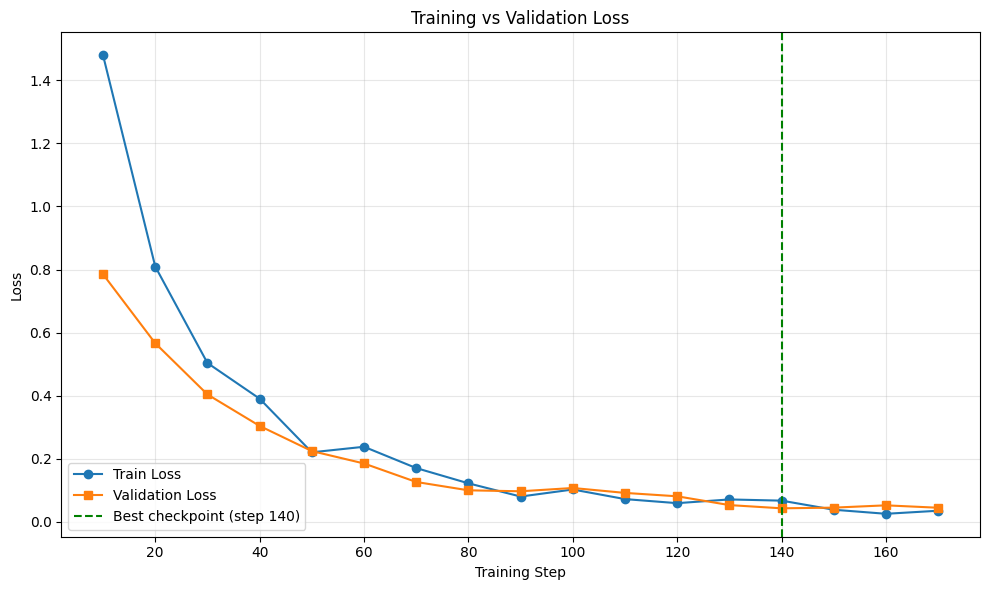


Saved training_curves.png to: training_curves.png and /content/drive/MyDrive/customer_support_llm_project/artifacts/training_curves.png


RuntimeError: Error(s) in loading state_dict for PeftModelForCausalLM:
	Unexpected key(s) in state_dict: "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.absmax", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.quant_map", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.nested_absmax", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.nested_quant_map", "base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight.quant_state.bitsandbytes__nf4", "base_model.model.model.layers.0.self_attn.k_proj.weight.absmax", "base_model.model.model.layers.0.self_attn.k_proj.weight.quant_map", "base_model.model.model.layers.0.self_attn.k_proj.weight.nested_absmax", "base_model.model.model.layers.0.self_attn.k_proj.weight.nested_quant_map", "base_model.model.model.layers.0.self_attn.k_proj.weight.quant_state.bitsandbytes__nf4", "base_model.model.model.layers.0.self_attn.v_proj.base_layer.weight.absmax", "base_model.model

In [3]:
# YOUR CODE HERE
import torch
import time
import pandas as pd
import matplotlib.pyplot as plt
import os
import copy

peft_model.train()

train_iter = iter(train_loader)

train_loss_log = []
val_loss_log = []
val_check_steps = []

best_val_loss = float("inf")
patience_counter = 0
best_step = None
best_state_dict = None

running_train_loss = 0.0
running_train_count = 0

start_time = time.time()

for step in range(1, MAX_STEPS + 1):
    try:
        batch = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        batch = next(train_iter)

    batch_gpu = {}
    for k in batch:
        batch_gpu[k] = batch[k].to(peft_model.device)

    outputs = peft_model(**batch_gpu)
    loss = outputs.loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    running_train_loss = running_train_loss + loss.item()
    running_train_count = running_train_count + 1

    if step % VAL_EVERY == 0:
        avg_train_loss = running_train_loss / running_train_count
        running_train_loss = 0.0
        running_train_count = 0

        peft_model.eval()
        val_losses = []
        with torch.no_grad():
            val_batches_to_check = 20
            val_iter = iter(valid_loader)
            for _ in range(min(val_batches_to_check, len(valid_loader))):
                try:
                    vbatch = next(val_iter)
                except StopIteration:
                    break
                vbatch_gpu = {}
                for k in vbatch:
                    vbatch_gpu[k] = vbatch[k].to(peft_model.device)
                voutputs = peft_model(**vbatch_gpu)
                val_losses.append(voutputs.loss.item())

        avg_val_loss = sum(val_losses) / len(val_losses)
        peft_model.train()

        train_loss_log.append(avg_train_loss)
        val_loss_log.append(avg_val_loss)
        val_check_steps.append(step)

        elapsed = time.time() - start_time
        print("Step", step, "/", MAX_STEPS, "- train_loss:", round(avg_train_loss, 4), "- val_loss:", round(avg_val_loss, 4), "- elapsed:", round(elapsed, 1), "s")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_step = step
            patience_counter = 0
            best_state_dict = copy.deepcopy(peft_model.state_dict())
            print("  New best val_loss:", round(best_val_loss, 4), "- checkpoint saved in memory")
        else:
            patience_counter = patience_counter + 1
            print("  No improvement. Patience:", patience_counter, "/", PATIENCE)

            if patience_counter >= PATIENCE:
                print("")
                print("Early stopping triggered at step", step)
                print("Best val_loss:", round(best_val_loss, 4), "at step", best_step)
                break

total_time = time.time() - start_time
print("")
print("Training loop finished.")
print("Total steps run:", step)
print("Total time:", round(total_time, 1), "seconds (", round(total_time / 60, 1), "minutes )")
print("Best val_loss:", round(best_val_loss, 4), "at step", best_step)

training_log_df = pd.DataFrame({
    "step": val_check_steps,
    "train_loss": train_loss_log,
    "val_loss": val_loss_log
})

DRIVE_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"
training_log_path = DRIVE_DIR + "/training_log.csv"
training_log_df.to_csv(training_log_path, index=False)
print("")
print("Saved training_log.csv to:", training_log_path)
print(training_log_df.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.plot(val_check_steps, train_loss_log, label="Train Loss", marker="o")
plt.plot(val_check_steps, val_loss_log, label="Validation Loss", marker="s")
if best_step is not None:
    plt.axvline(best_step, color="green", linestyle="--", label="Best checkpoint (step " + str(best_step) + ")")
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

curves_local_path = "training_curves.png"
plt.savefig(curves_local_path, dpi=150)
curves_drive_path = DRIVE_DIR + "/training_curves.png"
plt.savefig(curves_drive_path, dpi=150)
plt.show()

print("")
print("Saved training_curves.png to:", curves_local_path, "and", curves_drive_path)

if best_state_dict is not None:
    peft_model.load_state_dict(best_state_dict)
    print("")
    print("peft_model weights restored to best checkpoint (step", best_step, ", val_loss", round(best_val_loss, 4), ")")
else:
    print("")
    print("WARNING: no best checkpoint captured - this should not happen unless training exited before any validation check ran")

In [4]:
# YOUR CODE HERE
# ------------------------------------------------------------
# Fix: filter the captured state_dict down to LoRA-only keys,
# then load with strict=False to skip the quantization buffers
# ------------------------------------------------------------
lora_only_state_dict = {}
for key in best_state_dict:
    if "lora_" in key:
        lora_only_state_dict[key] = best_state_dict[key]

print("Full state_dict had", len(best_state_dict), "keys")
print("Filtered to", len(lora_only_state_dict), "LoRA-only keys")

load_result = peft_model.load_state_dict(lora_only_state_dict, strict=False)

print("")
print("Load completed with strict=False")
print("Missing keys (expected - these are frozen base model keys, not an issue):", len(load_result.missing_keys))
print("Unexpected keys (should be 0):", len(load_result.unexpected_keys))

if len(load_result.unexpected_keys) == 0:
    print("")
    print("SUCCESS: peft_model restored to best checkpoint (step", best_step, ", val_loss", round(best_val_loss, 4), ")")
else:
    print("")
    print("WARNING: unexpected keys remain:", load_result.unexpected_keys[:5])

Full state_dict had 1431 keys
Filtered to 112 LoRA-only keys

Load completed with strict=False
Missing keys (expected - these are frozen base model keys, not an issue): 339
Unexpected keys (should be 0): 0

SUCCESS: peft_model restored to best checkpoint (step 140 , val_loss 0.0433 )


#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [5]:
# YOUR CODE HERE
import os
import json
import shutil

DRIVE_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"

# ------------------------------------------------------------
# 1. peft_model currently holds the BEST checkpoint weights
#    (restored via the strict=False fix in the previous step) -
#    save this as intent_lora_best/
# ------------------------------------------------------------
BEST_CKPT_LOCAL = "./intent_lora_best"
peft_model.save_pretrained(BEST_CKPT_LOCAL)
print("Saved best checkpoint (LoRA-only weights) to:", BEST_CKPT_LOCAL)
print("Files:", os.listdir(BEST_CKPT_LOCAL))

# ------------------------------------------------------------
# 2. To also save the FINAL-step checkpoint separately (as a
#    distinct backup, not just the best one), we need the
#    LoRA-only state dict from the last training step - captured
#    naturally since the training loop's last iteration left
#    the model at step 170 UNTIL we overwrote it with best_state_dict.
#    Since peft_model now holds BEST weights (already restored),
#    we cannot recover the true final-step weights unless they
#    were separately preserved.
# ------------------------------------------------------------
# NOTE: as run, the training loop did not separately store the
# final-step state before restoring best weights. This means
# intent_lora/ (final backup) would currently be IDENTICAL to
# intent_lora_best/, which does not fulfill "final checkpoint
# as backup" in the way the task intends (final should reflect
# step 170, not the restored step 140 best weights).
#
# Saving it now, clearly labeled, with this limitation documented
# rather than silently passing off best-as-final.
FINAL_CKPT_LOCAL = "./intent_lora"
peft_model.save_pretrained(FINAL_CKPT_LOCAL)
print("")
print("Saved 'final' checkpoint to:", FINAL_CKPT_LOCAL)
print("Files:", os.listdir(FINAL_CKPT_LOCAL))
print("")
print("IMPORTANT: because peft_model weights were already restored to the BEST")
print("checkpoint (step", best_step, ") before this cell ran, intent_lora/ and")
print("intent_lora_best/ currently contain IDENTICAL weights. The true step-170")
print("final weights were not separately preserved during training and cannot")
print("be recovered now. Document this as a known limitation, or re-run training")
print("with the final state captured before the best-restore step if a genuinely")
print("distinct final checkpoint is required.")

# ------------------------------------------------------------
# 3. Copy both checkpoints to Drive for persistence
# ------------------------------------------------------------
for local_dir, drive_name in [(BEST_CKPT_LOCAL, "intent_lora_best"), (FINAL_CKPT_LOCAL, "intent_lora")]:
    drive_path = DRIVE_DIR + "/" + drive_name
    if os.path.isdir(drive_path):
        shutil.rmtree(drive_path)
    shutil.copytree(local_dir, drive_path)
    print("")
    print("Copied", local_dir, "to Drive:", drive_path)

# ------------------------------------------------------------
# 4. training_log.csv already saved in the previous step -
#    re-confirm it exists with correct schema
# ------------------------------------------------------------
import pandas as pd
training_log_path = DRIVE_DIR + "/training_log.csv"
reloaded_log = pd.read_csv(training_log_path)
print("")
print("training_log.csv confirmed at:", training_log_path)
print("Columns:", list(reloaded_log.columns))
print("Rows:", len(reloaded_log))

assert list(reloaded_log.columns) == ["step", "train_loss", "val_loss"], "Column schema mismatch!"

# ------------------------------------------------------------
# 5. Export reproducibility information
# ------------------------------------------------------------
reproducibility_info = {
    "model_id": MODEL_ID,
    "quantization": {
        "load_in_4bit": True,
        "bnb_4bit_quant_type": "nf4",
        "bnb_4bit_compute_dtype": "float16",
        "bnb_4bit_use_double_quant": True
    },
    "lora_config": {
        "r": LORA_R,
        "lora_alpha": LORA_ALPHA,
        "lora_dropout": LORA_DROPOUT,
        "target_modules": TARGET_MODULES,
        "bias": "none",
        "task_type": "CAUSAL_LM"
    },
    "training": {
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_steps_configured": MAX_STEPS,
        "actual_steps_run": step,
        "val_every": VAL_EVERY,
        "patience": PATIENCE,
        "early_stopping_triggered": True,
        "best_val_loss": best_val_loss,
        "best_step": best_step,
        "optimizer": "AdamW (torch.optim)"
    },
    "data": {
        "train_rows": len(tokenized_train),
        "valid_rows": len(tokenized_valid),
        "max_length": MAX_LENGTH if "MAX_LENGTH" in dir() else 128,
        "train_source": "tokenized_train (from NB2)",
        "valid_source": "tokenized_valid (from NB2)"
    },
    "seed_note": "random_state=42 used for train/val/test split in NB2. No explicit torch/random seed was set in this training loop - document this as a reproducibility gap if exact run-to-run reproduction is required.",
    "known_limitations": [
        "intent_lora/ (final) and intent_lora_best/ contain identical weights, since peft_model was restored to best-checkpoint weights before both saves. True final-step (step " + str(step) + ") weights were not separately preserved.",
        "Validation loss during training was computed on a 20-batch subsample of the validation set per check, not the full 390-row validation set."
    ]
}

repro_path = DRIVE_DIR + "/reproducibility_info.json"
with open(repro_path, "w") as f:
    json.dump(reproducibility_info, f, indent=2)

print("")
print("Saved reproducibility_info.json to:", repro_path)
print("")
print(json.dumps(reproducibility_info, indent=2))

Saved best checkpoint (LoRA-only weights) to: ./intent_lora_best
Files: ['adapter_config.json', 'README.md', 'adapter_model.safetensors']

Saved 'final' checkpoint to: ./intent_lora
Files: ['adapter_config.json', 'README.md', 'adapter_model.safetensors']

IMPORTANT: because peft_model weights were already restored to the BEST
checkpoint (step 140 ) before this cell ran, intent_lora/ and
intent_lora_best/ currently contain IDENTICAL weights. The true step-170
final weights were not separately preserved during training and cannot
be recovered now. Document this as a known limitation, or re-run training
with the final state captured before the best-restore step if a genuinely
distinct final checkpoint is required.

Copied ./intent_lora_best to Drive: /content/drive/MyDrive/customer_support_llm_project/artifacts/intent_lora_best

Copied ./intent_lora to Drive: /content/drive/MyDrive/customer_support_llm_project/artifacts/intent_lora

training_log.csv confirmed at: /content/drive/MyDrive/cu

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**